<a href="https://colab.research.google.com/github/Business-Intelligence-Book/Business-Intelligence-Book/blob/main/labs/09-classification-2/walkthrough/walkthrough.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color:#2F5597"><span style="background:#2F5597;color:#fff;padding:2px 10px;border-radius:3px">Lab 09</span>&nbsp; Classification II</h1>

<p style="color:#595959"><b style="color:#C55A11">Walkthrough</b> · k-nearest neighbors and decision trees · <i>Business Intelligence and Analytics</i> · Chapter 8</p>

<div style="background:#FFF2CC;border-radius:10px;padding:14px 20px;margin:12px 0;color:#222">
<p style="margin:0 0 6px 0"><b style="color:#C55A11">💡 What you will learn this week</b></p>
<ul style="margin:0">
<li>How the k-nearest neighbors classifier works, and why features must be normalized</li>
<li>How a decision tree makes its predictions</li>
<li>How to compare classifiers on a test set</li>
</ul>
</div>

Run the cells from top to bottom. Text cells explain each step; code cells show how to do it in Python.

---

# Classification 2: k-nearest neighbors and decision trees

Many algorithms can be used for classification, for example:
- Logistic regression (seen in the previous lab)
- k-nearest neighbors
- Decision trees
- Random forests
- Gradient boosting

This lab covers **k-nearest neighbors** and **decision trees**.

<div style="background:#E8EEF7;border-radius:10px;padding:14px 20px;margin:12px 0;color:#222">
<p style="margin:0 0 6px 0"><b style="color:#2F5597">⭐ Fun fact: A simple rule with a strong guarantee</b></p>
The nearest-neighbor rule was first described in 1951 by Evelyn Fix and Joseph Hodges, in a technical report for the US Air Force School of Aviation Medicine. In 1967 Thomas Cover and Peter Hart proved a surprising result: with enough data, the error rate of the simple 1-nearest-neighbor rule is at most twice that of the best possible classifier.
</div>

In this walkthrough we use a dataset on the *characteristics of fruits* and show two new classification algorithms: __k-nearest neighbors__ and __decision trees__. Whatever the algorithm, the steps are the same:
- Load the dataset
- Define the dependent and independent variables
- Split the dataset into a train set and a test set
- Normalize the data
- Create the model (logistic regression, KNN, decision tree, ...)
- Train the model
- Check the accuracy

In [1]:
#Load dataset
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

url = 'https://raw.githubusercontent.com/Business-Intelligence-Book/Business-Intelligence-Book/main/labs/data/fruitsII_2025.csv'
fruits = pd.read_csv(url,sep=";")
fruits.head()

,fruit_label,fruit_name,fruit_subtype,mass,width,height,color_score
0,1,apple,cripps_pink,161,7.4,7.0,0.82
1,1,apple,golden_delicious,153,7.7,7.4,0.70
2,1,apple,cripps_pink,162,7.4,7.2,0.85
3,1,apple,golden_delicious,165,7.4,7.8,0.71
4,1,apple,braeburn,171,7.3,6.9,0.88


We want to predict the class (`fruit_label`) from the other features.

In [2]:
#Define features and target variable
X = fruits[['mass', 'width', 'height', 'color_score']]
y = fruits['fruit_label']

In [3]:
X.shape

(89, 4)

Let's see the different classes:

In [4]:
print(fruits['fruit_name'].unique())

<StringArray>
['apple', 'orange']
Length: 2, dtype: str


In [5]:
print(fruits.fruit_label.unique())

[1 2]


There are two classes. A new observation (fruit) will therefore be classified either as an apple (1) or as an orange (2).

### 1. Split into train and test set

The data is split at random into a train set and a test set. The model learns from the train set, where the output is known, so that it can generalize to other data. We then check its predictions on the test set. By default, `train_test_split` uses 75% of the data for training and 25% for testing.

In [6]:
#Split data set into a train and a test data sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=24)

Let's take a quick look at the features in `X_train`.

In [7]:
X_train.describe()

,mass,width,height,color_score
count,66.000000,66.000000,66.000000,66.000000
mean,183.696970,7.557576,7.740909,0.770455
std,60.603623,0.662875,0.698565,0.076247
min,138.000000,6.600000,6.700000,0.550000
25%,153.250000,7.125000,7.225000,0.740000
50%,161.000000,7.400000,7.600000,0.765000
75%,179.750000,7.675000,7.900000,0.810000
max,364.000000,9.700000,9.500000,0.930000


### 2. Normalization

When the features of a dataset have very different ranges (for example an age between 0 and 99 years, and an income between 1,000 and 200,000), the results can be biased. We want the features to be in the same or a similar range, so we **normalize** the data: we scale the values of each feature so that they fall within a small specified range.
We can use `StandardScaler()`, `MinMaxScaler()` or other scalers.
<br>

In this example we normalize the **train AND test set** with `MinMaxScaler`, which gives all features values between 0 and 1.

**Important**: fit the scaler on the train set only, then apply the same transformation to the test set.

In [8]:
#Define normalization
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaler.fit(X_train)

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](4,)","[364. , 9.7 , 9.5 , 0.93]"
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](4,)","[138. , 6.6 , 6.7 , 0.55]"
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](4,)","[226. , 3.1 , 2.8 , 0.38]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['mass','width','height','color_score']"
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](4,)","[-0.61,-2.13,-2.39,-1.45]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,66


In [9]:
#Apply normalization
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

Let's check that the features in `X_train` are normalized: all values are between 0 and 1.

In [10]:
pd.DataFrame(X_train, columns=['mass', 'width', 'height', 'color_score']).describe()

,mass,width,height,color_score
count,66.000000,66.000000,66.000000,66.000000
mean,0.202199,0.308895,0.371753,0.580144
std,0.268158,0.213831,0.249487,0.200651
min,0.000000,0.000000,0.000000,0.000000
25%,0.067478,0.169355,0.187500,0.500000
50%,0.101770,0.258065,0.321429,0.565789
75%,0.184735,0.346774,0.428571,0.684211
max,1.000000,1.000000,1.000000,1.000000


### 3. K-nearest neighbors

The KNN algorithm assigns a new example to the most common class among its K nearest neighbors. If k = 1, the example simply gets the class of its nearest neighbor. If k = 5, the class is decided by a majority vote of the 5 nearest data points. KNN is simple to implement, robust to noisy training data, and effective when the training set is large. On the other hand, we need to choose the value of K, and the computation is costly because the distance to every training sample must be computed. <br>

As before, we first create the model and build it on the **training set**. The dataset is already split into **training** and **test sets**.

When we create the model, we specify **how many neighbors** to consider.

In [11]:
#Create model with K=11
from sklearn.neighbors import KNeighborsClassifier
model_k11 = KNeighborsClassifier(n_neighbors=11)

In [12]:
#Fit model
model_k11.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",11
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [13]:
#Use model on test and check accuracy

print('Accuracy of KNN classifier on test set: {:.2f}'
     .format(model_k11.score(X_test, y_test)))

print('Accuracy of KNN classifier on training set: {:.2f}'
     .format(model_k11.score(X_train, y_train)))

Accuracy of KNN classifier on test set: 0.96
Accuracy of KNN classifier on training set: 0.94


We chose k = 11 arbitrarily. Another value may give a better accuracy, and we can change other parameters too: **weights**, to give less importance to faraway points, and **p**, to change how the distance between two points is computed (see the [p-norm](https://en.wikipedia.org/wiki/Minkowski_distance)). Let's try different values.

The parameters are:
- `n_neighbors`: the number of neighbors to use.
- `p`: the distance metric. p = 1 is the Manhattan distance (l1), p = 2 the Euclidean distance (l2).
- `weights`: how to weigh the neighbors.
  - `uniform`: all the points in a neighborhood have the same weight.
  - `distance`: points are weighted by the inverse of their distance, so closer neighbors have more influence than neighbors further away.

For the full list of parameters, see the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html).

In [14]:
n_neighbors = [2,3,4,5]
p_values = [1,2,3]
weights = ['uniform', 'distance']
for n in n_neighbors:
    for p in p_values:
        for w in weights:
            model = KNeighborsClassifier(n_neighbors=n, p=p, weights=w)
            model.fit(X_train, y_train)
            print("accuracy for k = " + str(n) + ", p = " + str(p) + ", weight = " + w + " : " + str(model.score(X_test, y_test)))

accuracy for k = 2, p = 1, weight = uniform : 0.9565217391304348
accuracy for k = 2, p = 1, weight = distance : 0.9565217391304348
accuracy for k = 2, p = 2, weight = uniform : 0.9565217391304348
accuracy for k = 2, p = 2, weight = distance : 0.9565217391304348
accuracy for k = 2, p = 3, weight = uniform : 0.9565217391304348
accuracy for k = 2, p = 3, weight = distance : 0.9565217391304348
accuracy for k = 3, p = 1, weight = uniform : 1.0
accuracy for k = 3, p = 1, weight = distance : 1.0
accuracy for k = 3, p = 2, weight = uniform : 1.0
accuracy for k = 3, p = 2, weight = distance : 1.0
accuracy for k = 3, p = 3, weight = uniform : 1.0
accuracy for k = 3, p = 3, weight = distance : 1.0
accuracy for k = 4, p = 1, weight = uniform : 1.0
accuracy for k = 4, p = 1, weight = distance : 1.0
accuracy for k = 4, p = 2, weight = uniform : 1.0
accuracy for k = 4, p = 2, weight = distance : 1.0
accuracy for k = 4, p = 3, weight = uniform : 1.0
accuracy for k = 4, p = 3, weight = distance : 1.0
a

In [15]:
# You don't have to understand this code, it's just here to plot decision boundaries
from sklearn.inspection import DecisionBoundaryDisplay

def plot_knn_decision_boundaries(X, y, weights='uniform', metric='minkowski', n_neighbors_list=[1, 3, 5, 11]):
    # We'll use only two features for visualization
    X_subset = X[:, [1, 2]]  # Using width and height

    feature_names = ['width', 'height']

    # Set up the figure
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    axes = axes.flatten()
    cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])
    cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF', '#FFFF00'])

    for i, n_neighbors in enumerate(n_neighbors_list):
        # Create and fit the KNN classifier
        knn = KNeighborsClassifier(n_neighbors=n_neighbors, weights=weights, metric=metric)
        knn.fit(X_subset, y)

        # Plot decision boundary
        disp = DecisionBoundaryDisplay.from_estimator(
            knn,
            X_subset,
            cmap=cmap_light,
            alpha=0.5,
            ax=axes[i],
            response_method="predict",
        )
        scatter = axes[i].scatter(X_subset[:, 0], X_subset[:, 1], c=y, cmap=cmap_bold, edgecolor='k', s=50)
        legend = axes[i].legend(*scatter.legend_elements(), title="Classes")
        axes[i].add_artist(legend)

        axes[i].set_title(f'KNN (k={n_neighbors})')
        axes[i].set_xlabel(feature_names[0])
        axes[i].set_ylabel(feature_names[1])

    plt.tight_layout()
    plt.suptitle('KNN Decision Boundaries with Different k Values', y=1.05, fontsize=16)
    plt.show()

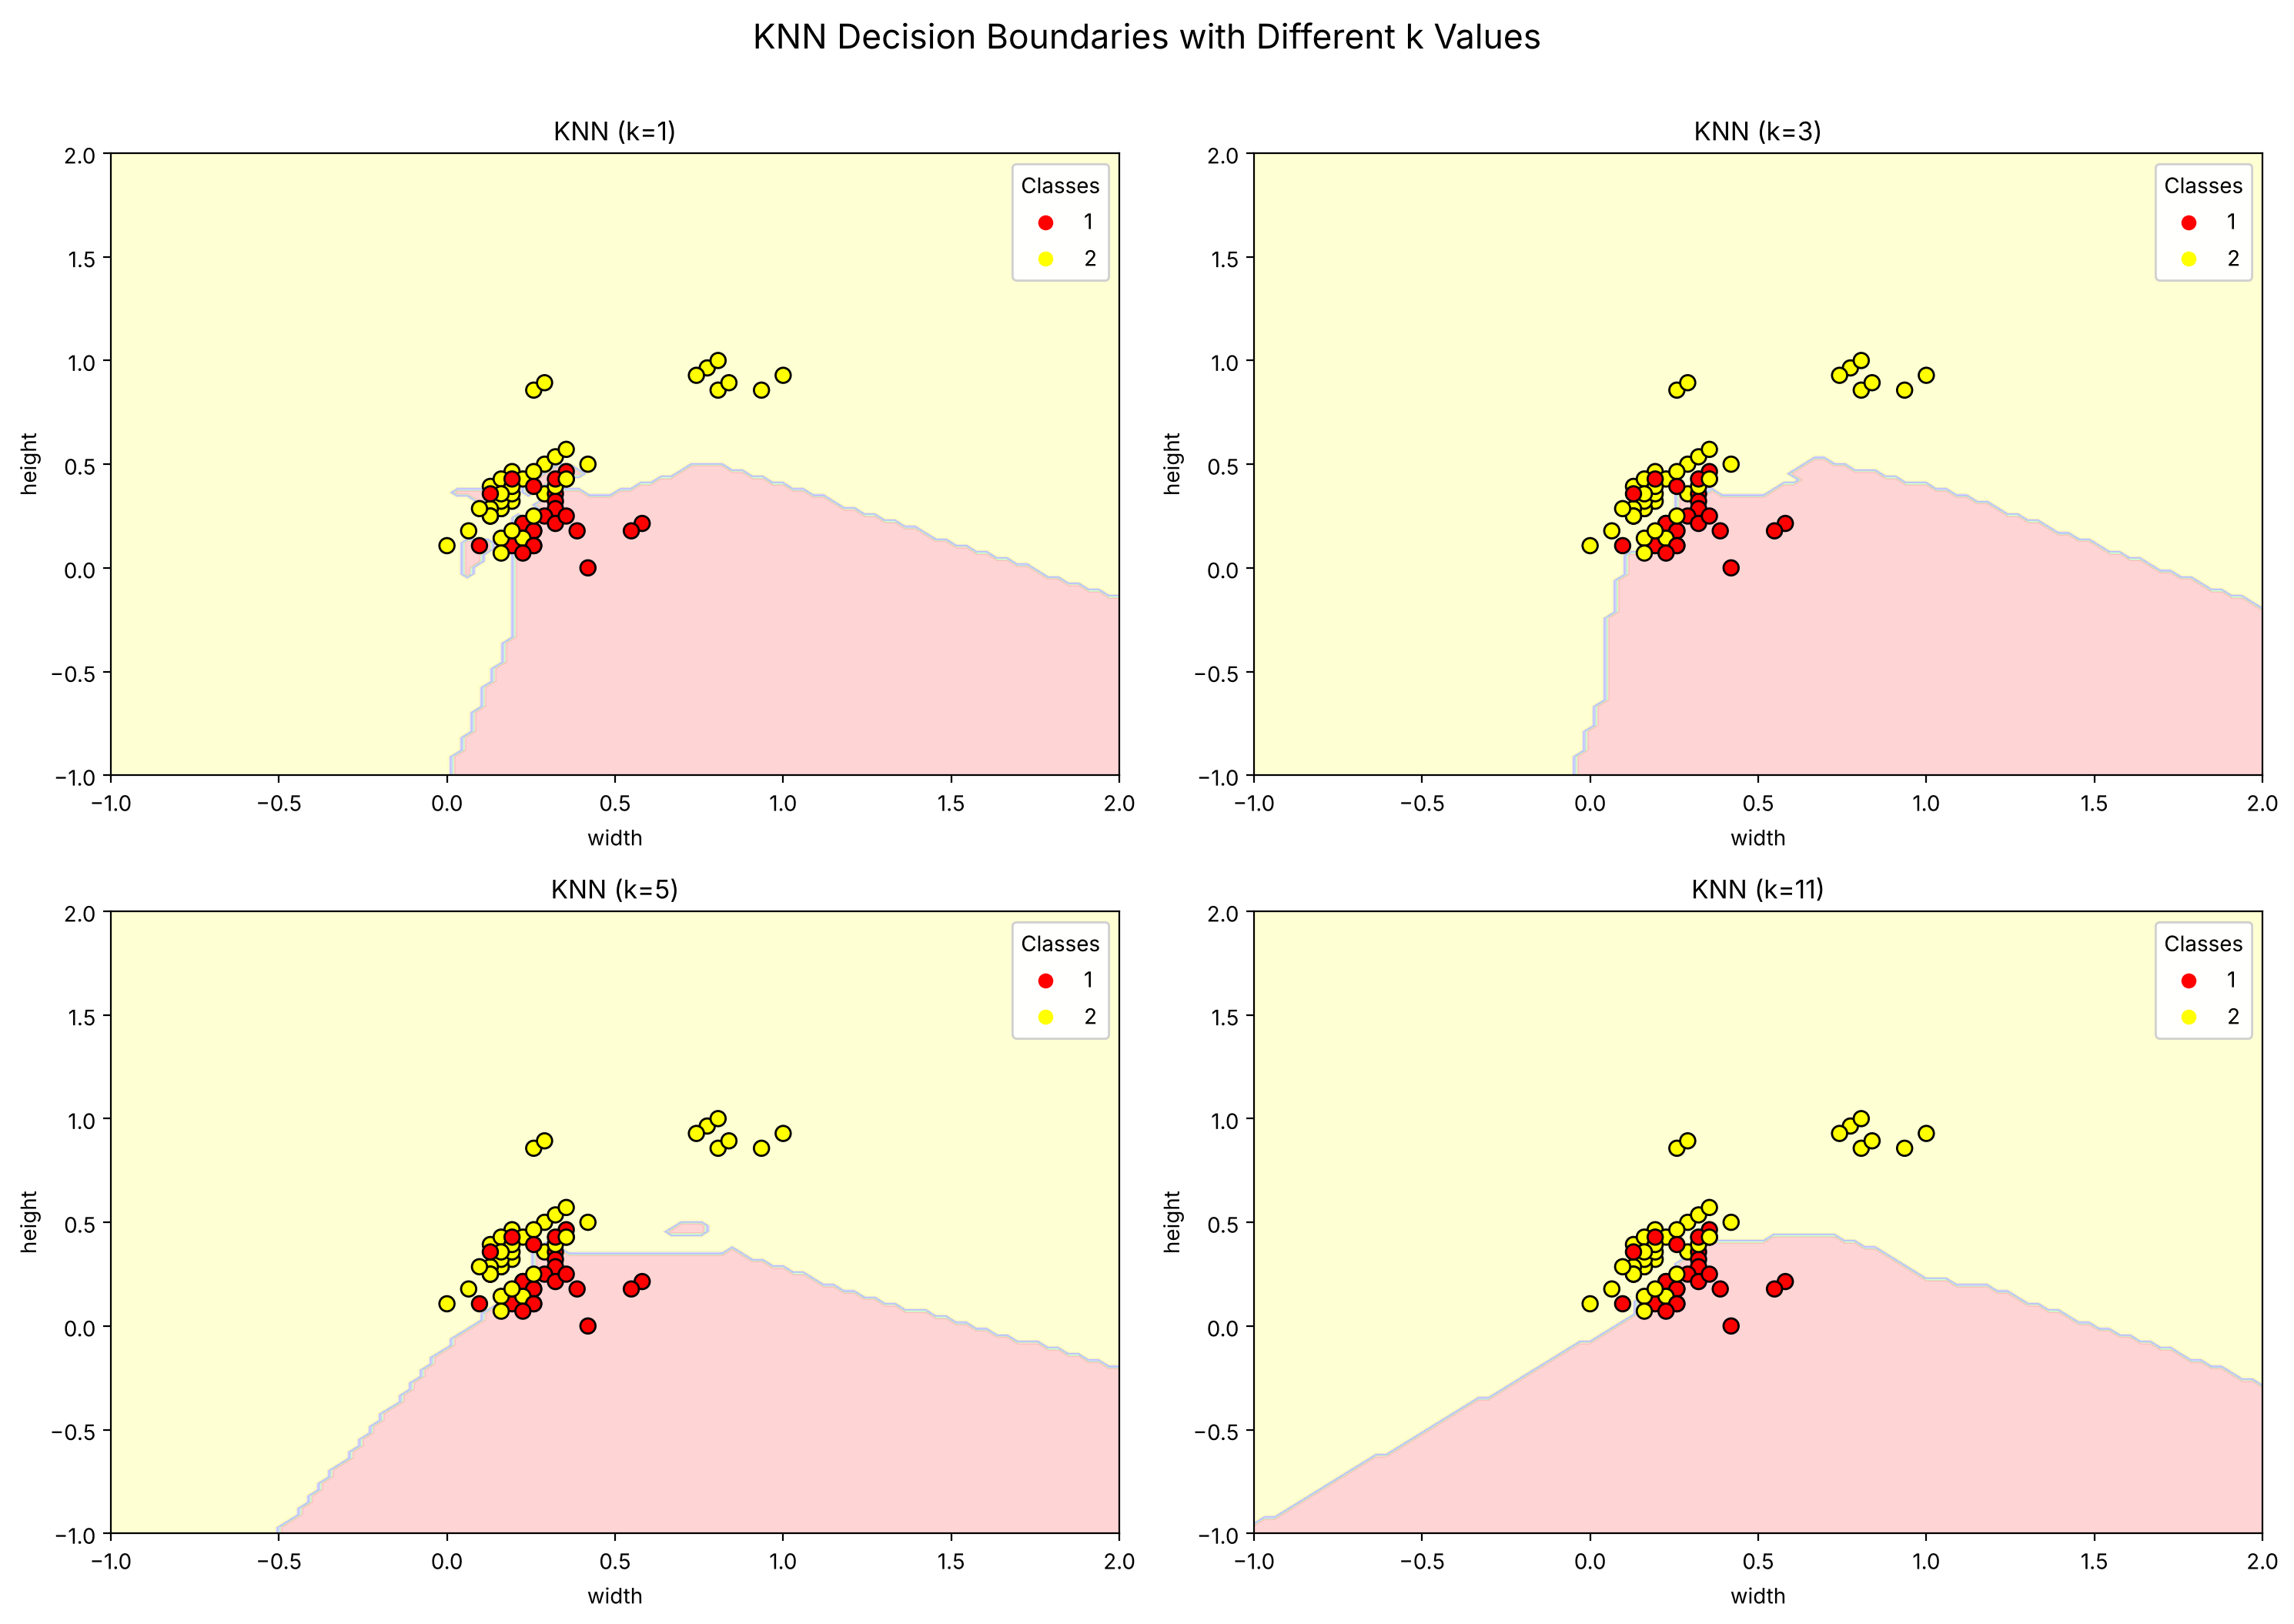

In [16]:
plot_knn_decision_boundaries(X_train, y_train)

### 4. Tuning hyperparameters with cross-validation

We now look for the best hyperparameters of the [KNN classifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html). For this we use [grid search with cross-validation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

In [17]:
# Grid Search - hyperparameter tuning
from sklearn.model_selection import GridSearchCV
import numpy as np

# Define parameters to test
grid = {'n_neighbors':np.arange(1,10),
        'p':np.arange(1,3),
        'weights':['uniform','distance']
       }

# Define and fit model
knn = KNeighborsClassifier()
knn_cv = GridSearchCV(knn, grid, cv=5)
knn_cv.fit(X_train, y_train)

# Print results
print("Hyperparameters:", knn_cv.best_params_)
print("Train Score:", round(knn_cv.best_score_, 4))
print("Test Score:", round(knn_cv.score(X_test, y_test), 4))

Hyperparameters: {'n_neighbors': np.int64(8), 'p': np.int64(1), 'weights': 'uniform'}
Train Score: 0.9549
Test Score: 0.9565


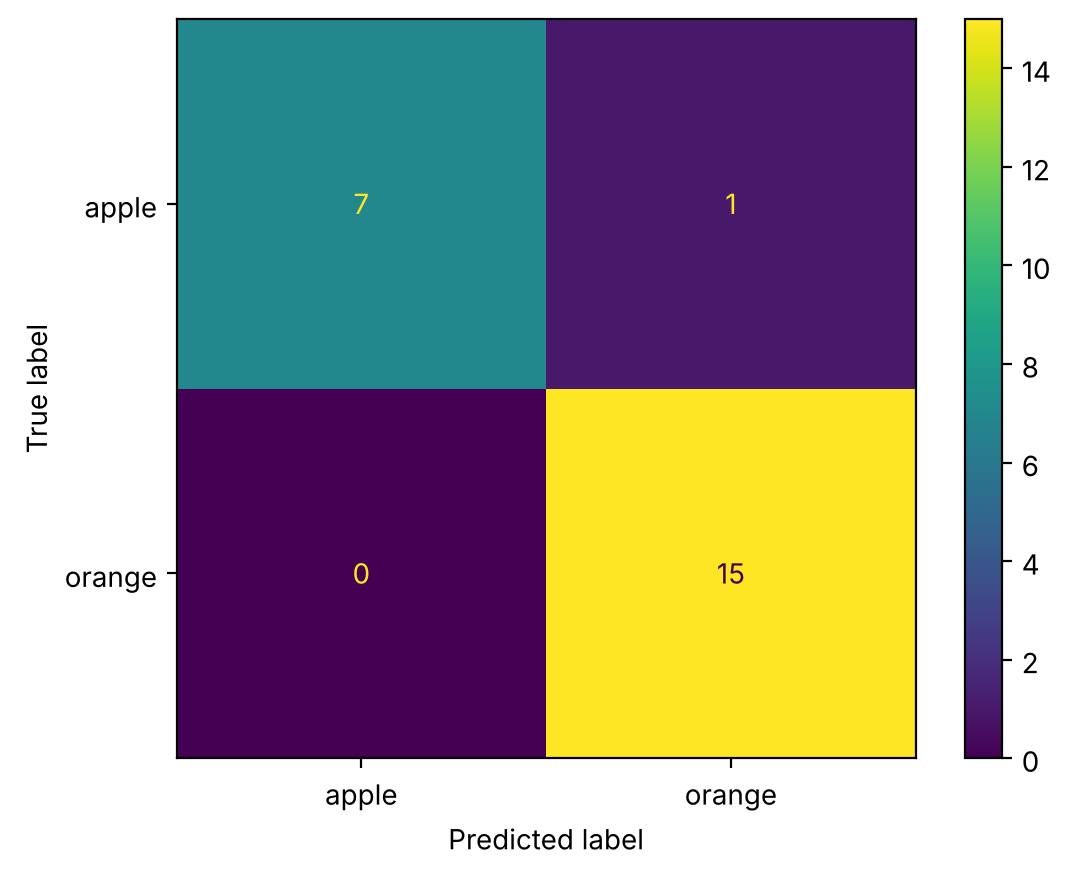


Classification Report:
              precision    recall  f1-score   support

           1       1.00      0.88      0.93         8
           2       0.94      1.00      0.97        15

    accuracy                           0.96        23
   macro avg       0.97      0.94      0.95        23
weighted avg       0.96      0.96      0.96        23


Micro and Macro Metrics:
 - Micro Precision: 0.957
 - Macro Precision: 0.969
 - Micro Recall: 0.957
 - Macro Recall: 0.938


In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay
import numpy as np


y_pred = knn_cv.predict(X_test)

# Get the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Create a heatmap with better visualization
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=knn_cv.classes_)

disp.plot()

classes = ['apple', 'orange']
tick_marks = np.arange(len(classes))
disp.ax_.set_xticks(tick_marks)
disp.ax_.set_yticks(tick_marks)
disp.ax_.set_xticklabels(classes)
disp.ax_.set_yticklabels(classes)
plt.show()
# Print detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Calculate micro and macro metrics
print("\nMicro and Macro Metrics:")
print(f" - Micro Precision: {precision_score(y_test, y_pred, average='micro'):.3f}")
print(f" - Macro Precision: {precision_score(y_test, y_pred, average='macro'):.3f}")
print(f" - Micro Recall: {recall_score(y_test, y_pred, average='micro'):.3f}")
print(f" - Macro Recall: {recall_score(y_test, y_pred, average='macro'):.3f}")

The model shows an **imbalance pattern**: perfect precision (1.00) but lower recall (0.88) for the minority apple class, versus perfect recall (1.00) but slightly lower precision (0.94) for the majority orange class. 

This suggests the model is more cautious when predicting the minority class, creating a precision-recall tradeoff 

### 5. Decision tree
A decision tree classifier predicts the class of a new data point with a sequence of rules. It is easy to understand and to visualize, and it can handle both numerical and categorical data.

 **Warning:** a decision tree can become too complex and generalize poorly (overfitting). It can also be unstable: a small change in the dataset may produce a completely different tree. <br>

Before building the tree, we set its maximum depth, the maximum number of levels of questions the tree may ask.

In [19]:
#create, fit and test model
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(max_depth=5, random_state=0)
model.fit(X_train, y_train)
print(model.score(X_test, y_test))

0.9565217391304348


The accuracy is high, but the model may be more complicated than necessary. Let's see whether a tree with a smaller maximum depth does as well.
First, a tree of depth 1:

In [20]:
model = DecisionTreeClassifier(max_depth=1, random_state=0)
model.fit(X_train, y_train)
print(model.score(X_test, y_test))

0.8260869565217391


In [21]:
# Test accuracy for trees of increasing depth: a depth of 2 is enough here,
# and trees deeper than 3 do slightly worse on the test set (a sign of overfitting)
for depth in range(1, 6):
    model = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_train, y_train)
    print(f"max_depth = {depth}: test accuracy = {model.score(X_test, y_test):.2f}")

max_depth = 1: test accuracy = 0.83
max_depth = 2: test accuracy = 1.00
max_depth = 3: test accuracy = 1.00
max_depth = 4: test accuracy = 0.91
max_depth = 5: test accuracy = 0.96


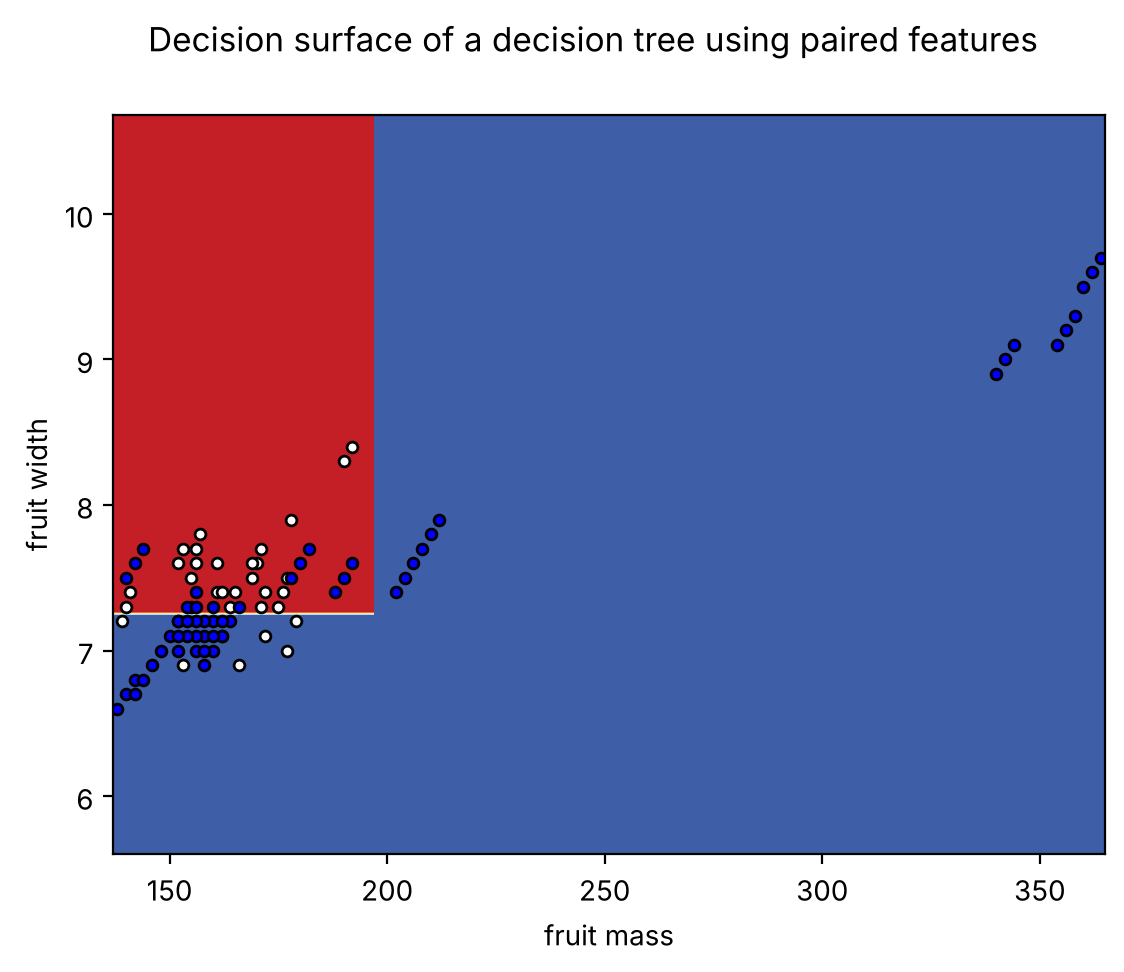

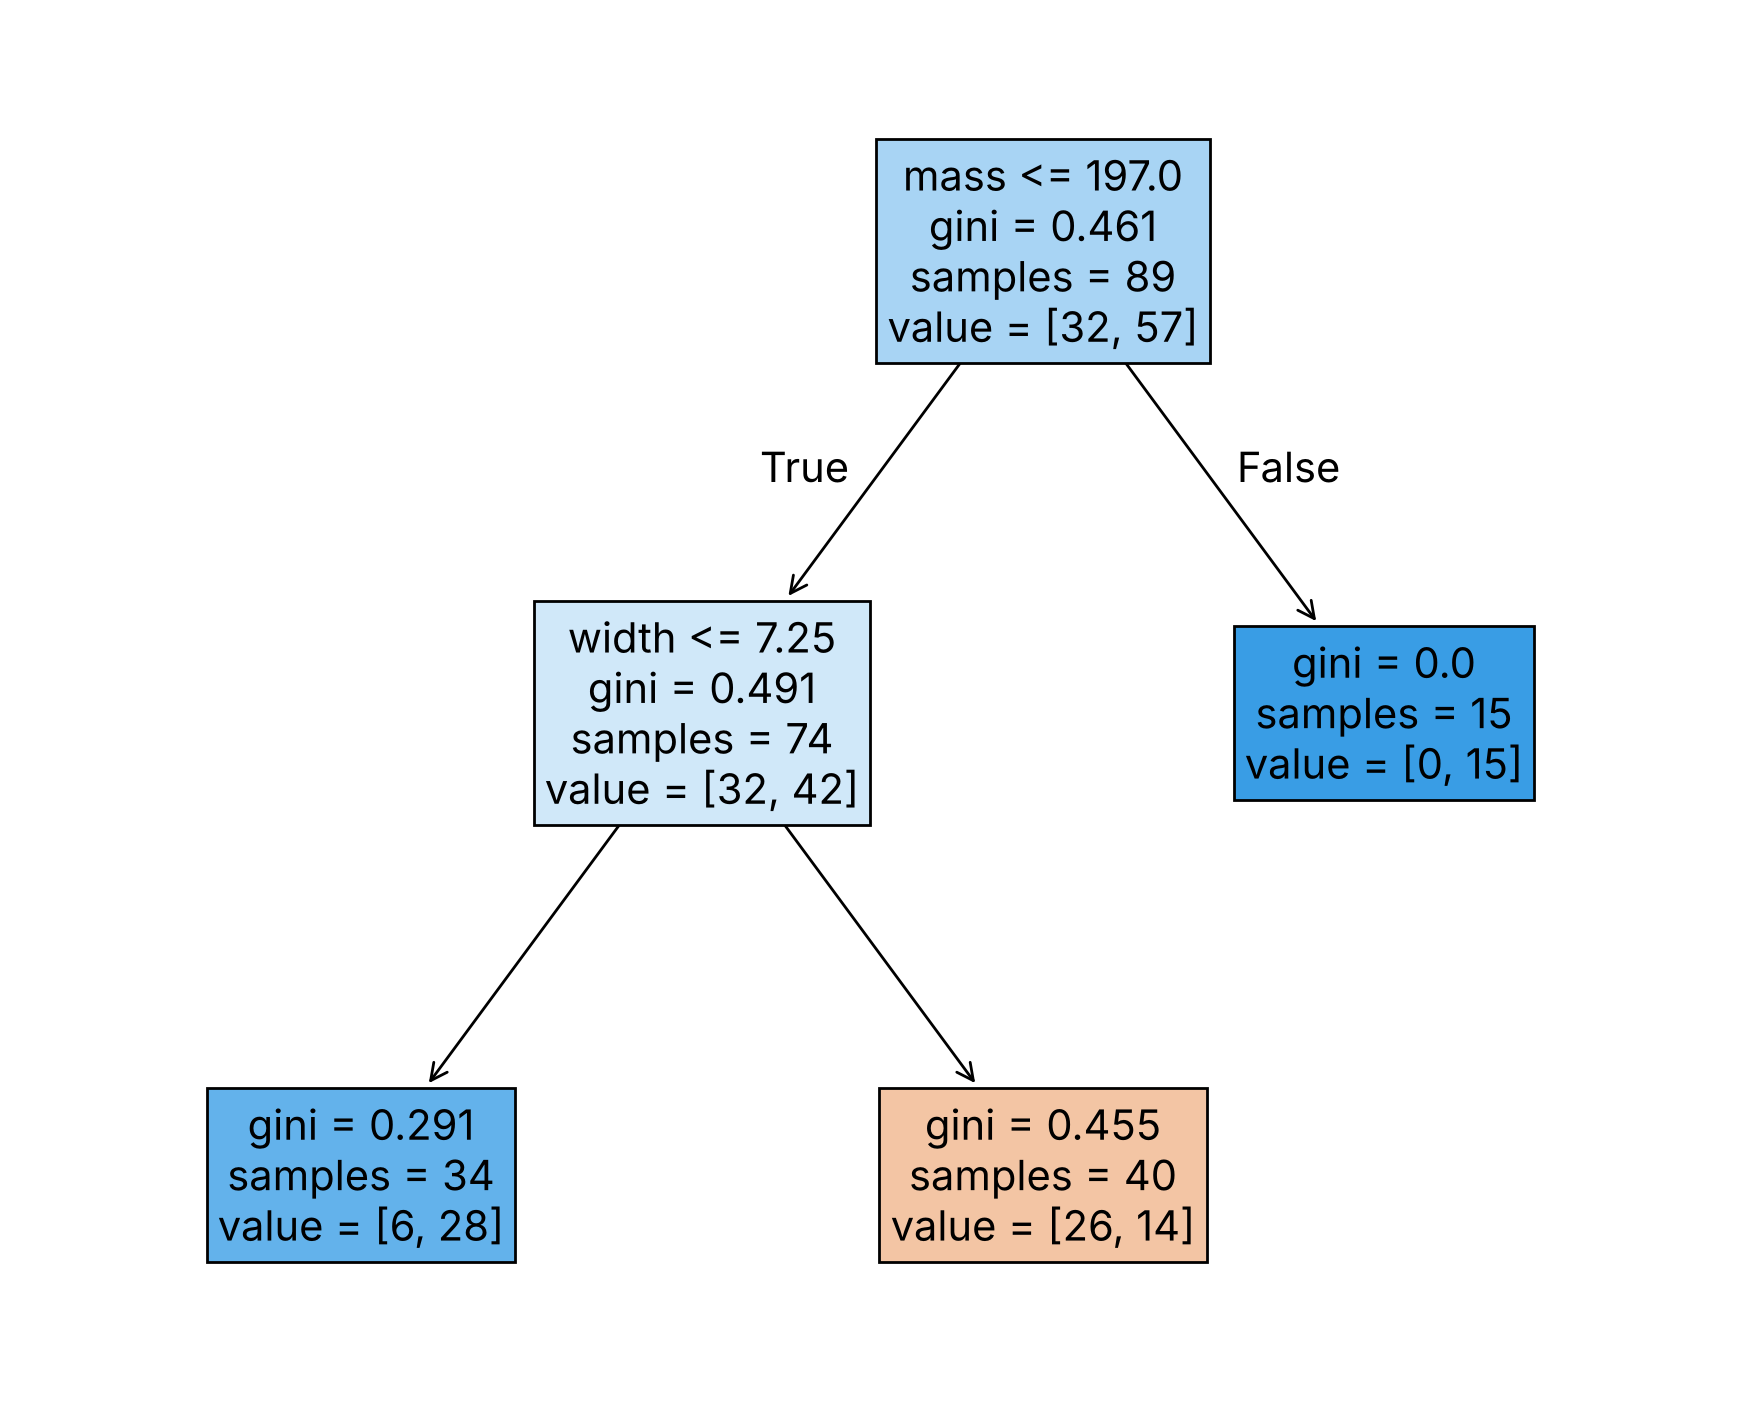

In [22]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree

plot_colors = "wb"
plot_step = 0.02


X = X[['mass', 'width']].values

clf = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X, y)

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step), np.arange(y_min, y_max, plot_step))
plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
cs = plt.contourf(xx, yy, Z, cmap=plt.cm.RdYlBu)

plt.xlabel('fruit mass')
plt.ylabel('fruit width')

# Plot the training points
for i, color in zip(range(2), plot_colors):
    idx = np.where(y == i+1)
    plt.scatter(X[idx, 0], X[idx, 1], c=color, edgecolor='black', s=15)

plt.suptitle("Decision surface of a decision tree using paired features")
plt.axis("tight")

plt.figure(figsize=(11,9))
clf = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X, y)
plot_tree(clf, filled=True, feature_names=('mass', 'width'), fontsize=15)
plt.show()

A few words about this decision tree, which is fitted on the whole dataset:  
It starts at the root, with all 89 samples: 32 belong to class 1 and 57 to class 2.
Each node is a condition that splits the data into two branches. The end of a branch that no longer splits is a leaf.
The Gini index measures the impurity of each node. It starts at 0.46 at the root, where the classes are mixed, and goes down towards 0 (a pure node) as we move down the tree.